In [1]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


# Assignment 10

The dataset records cumulative COVID-19 cases

In [4]:
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/refs/heads/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
covid = pd.read_csv(url)

us = covid[covid["Country/Region"] == "US"]
cases_cols = covid.columns[4:]
us_cases = us[cases_cols].sum(axis=0)

def daily_cases(cumulative):

    # calculate daily number of new cases between previous day
    daily = cumulative.diff()
    daily.iloc[0] = cumulative.iloc[0]

    data = pd.DataFrame({
        "date": daily.index,
        "Y": daily.to_numpy(dtype=float),
        "t": np.arange(len(daily))
    })

    return data.reset_index(drop=True)

def create_lags(data):
    
    df = data.copy()
    for i in range(1, 6):
        df[f"lag{i}"] = df["Y"].shift(i)
        
    df = df.dropna().reset_index(drop=True)
    return df

data = daily_cases(us_cases)
lags = create_lags(data)
lags

,date,Y,t,lag1,lag2,lag3,lag4,lag5
0,1/27/20,0.00,5,3.00,0.00,1.00,0.00,1.00
1,1/28/20,0.00,6,0.00,3.00,0.00,1.00,0.00
2,1/29/20,1.00,7,0.00,0.00,3.00,0.00,1.00
3,1/30/20,0.00,8,1.00,0.00,0.00,3.00,0.00
4,1/31/20,2.00,9,0.00,1.00,0.00,0.00,3.00
...,...,...,...,...,...,...,...,...
1133,3/5/23,"-3,862.00",1138,"2,147.00","58,933.00","55,885.00","90,417.00","43,628.00"
1134,3/6/23,"8,564.00",1139,"-3,862.00","2,147.00","58,933.00","55,885.00","90,417.00"
1135,3/7/23,"35,371.00",1140,"8,564.00","-3,862.00","2,147.00","58,933.00","55,885.00"
1136,3/8/23,"64,861.00",1141,"35,371.00","8,564.00","-3,862.00","2,147.00","58,933.00"


In [5]:
split = len(lags) // 2
X = lags[["lag1", "lag2", "lag3", "lag4", "lag5"]]
X_train = X.iloc[:split]
X_test = X.iloc[split:]
y = lags["Y"]
y_train = y.iloc[:split]
y_test = y.iloc[split:]

## A) Linear Regression

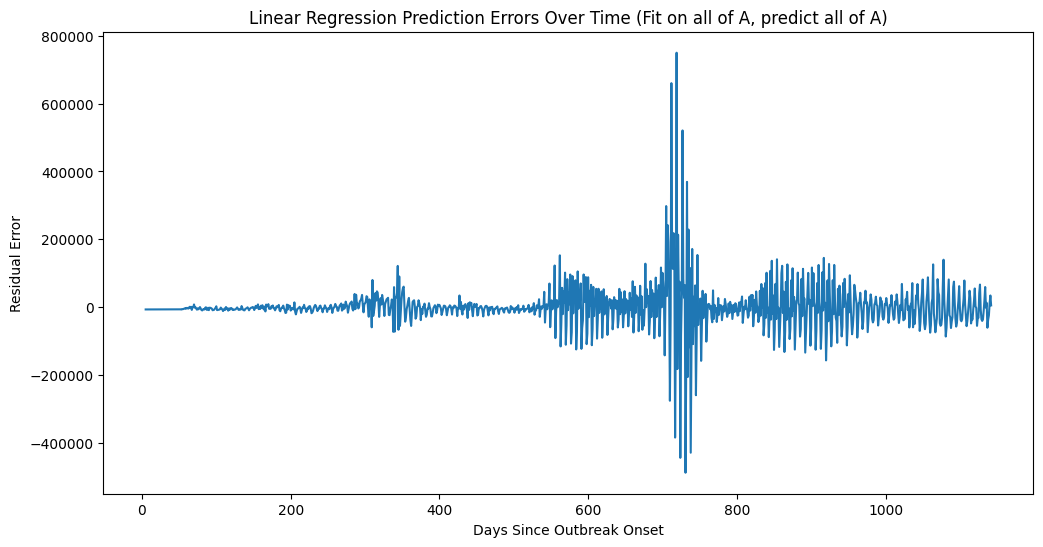

In [6]:
model_A = LinearRegression()
model_A.fit(X, y)

predict_all_A = model_A.predict(X)
residuals_A = y.to_numpy() - predict_all_A
mse_A = mean_squared_error(y, predict_all_A)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"], residuals_A)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Linear Regression Prediction Errors Over Time (Fit on all of A, predict all of A)")
plt.show()

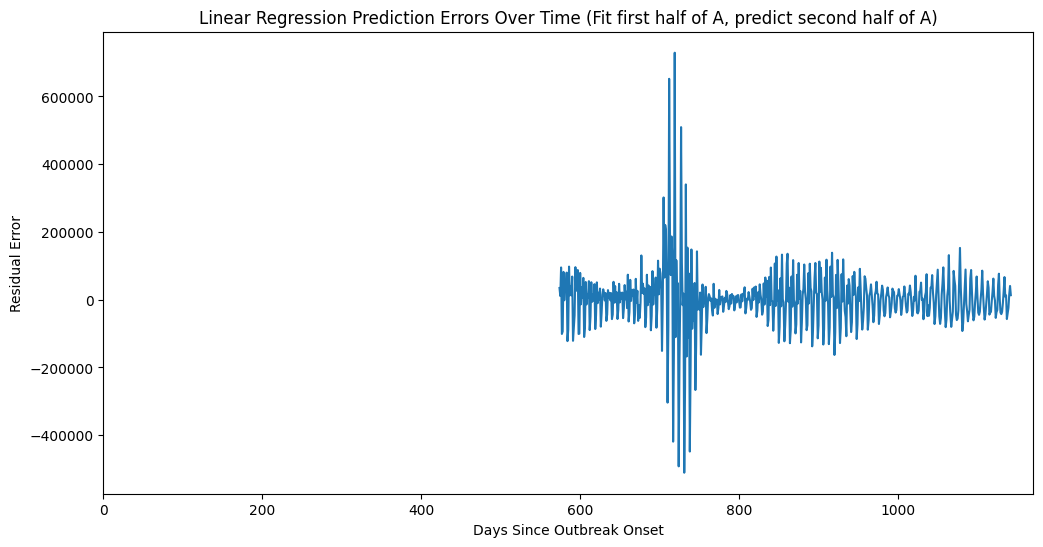

In [7]:
model_half_A = LinearRegression()
model_half_A.fit(X_train, y_train)

predict_half_A = model_half_A.predict(X_test)
residuals_half_A = y_test.to_numpy() - predict_half_A
mse_half_A = mean_squared_error(y_test, predict_half_A)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"].iloc[split:], residuals_half_A)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Linear Regression Prediction Errors Over Time (Fit first half of A, predict second half of A)")
plt.xlim(0, None)
plt.show()

In [8]:
print(mse_A)
print(mse_half_A)

4116667734.5562906
8025909480.660431


## B) Neural Network -- one hidden layer with 2 nodes

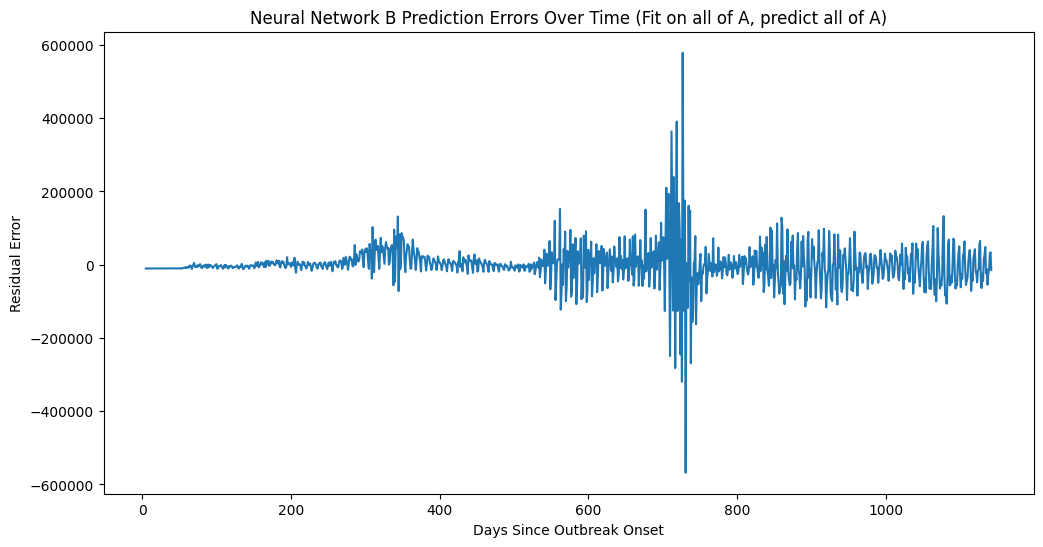

In [9]:
model_B = nn.Sequential(
    nn.Linear(5, 2),
    nn.ReLU(),
    nn.Linear(2, 1)
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_fit = torch.tensor(scaler_X.fit_transform(X), dtype=torch.float32)
y_fit = torch.tensor(scaler_y.fit_transform(y.to_numpy().reshape(-1, 1)), dtype=torch.float32)
optimizer = torch.optim.Adam(model_B.parameters(), lr=0.01)
loss_function = nn.MSELoss()

for epoch in range(1500):
    optimizer.zero_grad()
    loss = loss_function(model_B(X_fit), y_fit)
    loss.backward()
    optimizer.step()

X_predict = torch.tensor(scaler_X.transform(X), dtype=torch.float32)
with torch.no_grad():
    predict_B = scaler_y.inverse_transform(model_B(X_predict).numpy()).ravel()
residuals_B = y.to_numpy() - predict_B
mse_B = mean_squared_error(y, predict_B)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"], residuals_B)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Neural Network B Prediction Errors Over Time (Fit on all of A, predict all of A)")
plt.show()

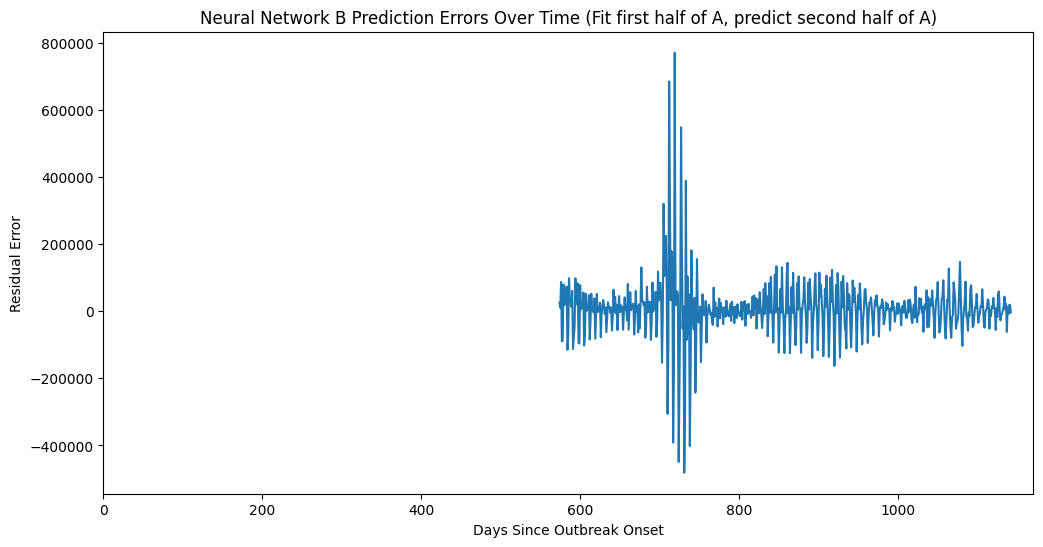

In [10]:
model_half_B = nn.Sequential(
    nn.Linear(5, 2),
    nn.ReLU(),
    nn.Linear(2, 1)
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_fit = torch.tensor(scaler_X.fit_transform(X_train), dtype=torch.float32)
y_fit = torch.tensor(scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)), dtype=torch.float32)
optimizer = torch.optim.Adam(model_half_B.parameters(), lr=0.01)
loss_function = nn.MSELoss()

for epoch in range(1500):
    optimizer.zero_grad()
    loss = loss_function(model_half_B(X_fit), y_fit)
    loss.backward()
    optimizer.step()

X_predict = torch.tensor(scaler_X.transform(X_test), dtype=torch.float32)
with torch.no_grad():
    predict_half_B = scaler_y.inverse_transform(model_half_B(X_predict).numpy()).ravel()
residuals_half_B = y_test.to_numpy() - predict_half_B
mse_half_B = mean_squared_error(y_test, predict_half_B)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"].iloc[split:], residuals_half_B)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Neural Network B Prediction Errors Over Time (Fit first half of A, predict second half of A)")
plt.xlim(0, None)
plt.show()

In [11]:
print(mse_B)
print(mse_half_B)

2896388280.259423
7955931716.619132


## C) Neural Network -- 2 hidden layers with 2 nodes each

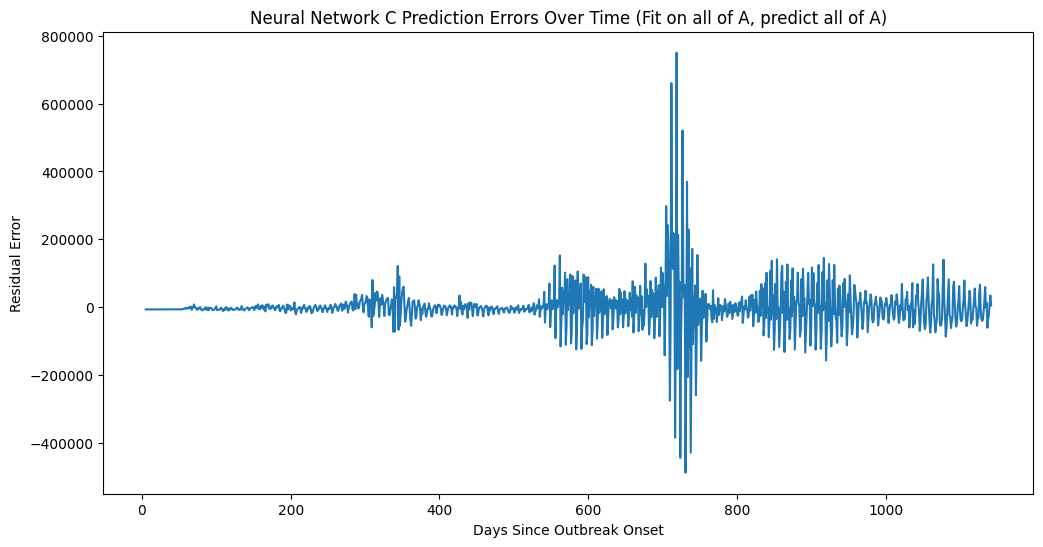

In [12]:
model_C = nn.Sequential(
    nn.Linear(5, 2),
    nn.ReLU(),
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1)
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_fit = torch.tensor(scaler_X.fit_transform(X), dtype=torch.float32)
y_fit = torch.tensor(scaler_y.fit_transform(y.to_numpy().reshape(-1, 1)), dtype=torch.float32)
optimizer = torch.optim.Adam(model_C.parameters(), lr=0.01)
loss_function = nn.MSELoss()

for epoch in range(1500):
    optimizer.zero_grad()
    loss = loss_function(model_C(X_fit), y_fit)
    loss.backward()
    optimizer.step()

X_predict = torch.tensor(scaler_X.transform(X), dtype=torch.float32)
with torch.no_grad():
    predict_C = scaler_y.inverse_transform(model_C(X_predict).numpy()).ravel()
residuals_C = y.to_numpy() - predict_C
mse_C = mean_squared_error(y, predict_C)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"], residuals_C)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Neural Network C Prediction Errors Over Time (Fit on all of A, predict all of A)")
plt.show()

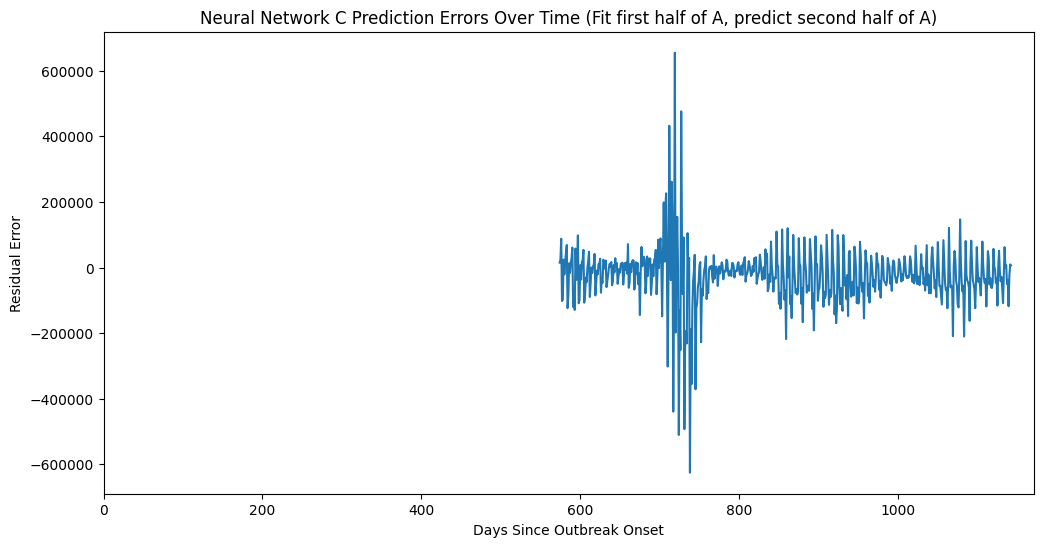

In [13]:
model_half_C = nn.Sequential(
    nn.Linear(5, 2),
    nn.ReLU(),
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1)
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_fit = torch.tensor(scaler_X.fit_transform(X_train), dtype=torch.float32)
y_fit = torch.tensor(scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)), dtype=torch.float32)
optimizer = torch.optim.Adam(model_half_C.parameters(), lr=0.01)
loss_function = nn.MSELoss()

for epoch in range(1500):
    optimizer.zero_grad()
    loss = loss_function(model_half_C(X_fit), y_fit)
    loss.backward()
    optimizer.step()

X_predict = torch.tensor(scaler_X.transform(X_test), dtype=torch.float32)
with torch.no_grad():
    predict_half_C = scaler_y.inverse_transform(model_half_C(X_predict).numpy()).ravel()
residuals_half_C = y_test.to_numpy() - predict_half_C
mse_half_C = mean_squared_error(y_test, predict_half_C)

plt.figure(figsize=(12, 6))
plt.plot(lags["t"].iloc[split:], residuals_half_C)
plt.xlabel("Days Since Outbreak Onset")
plt.ylabel("Residual Error")
plt.title("Neural Network C Prediction Errors Over Time (Fit first half of A, predict second half of A)")
plt.xlim(0, None)
plt.show()

In [14]:
print(mse_C)
print(mse_half_C)

4116667713.008789
8497829318.29753


## Model Comparison

In [15]:
results = pd.DataFrame({
    "Model": ["A: Linear Regression", "B: 1 Layer of 2 Hidden Nodes", "C: 2 Layers of 2 Hidden Nodes"],
    "MSE (Fit All, Predict All)": [mse_A, mse_B, mse_C],
    "MSE (Train First Half, Test Second Half)": [mse_half_A, mse_half_B, mse_half_C]
})
display(results.round(2))

,Model,"MSE (Fit All, Predict All)","MSE (Train First Half, Test Second Half)"
0,A: Linear Regression,"4,116,667,734.56","8,025,909,480.66"
1,B: 1 Layer of 2 Hidden Nodes,"2,896,388,280.26","7,955,931,716.62"
2,C: 2 Layers of 2 Hidden Nodes,"4,116,667,713.01","8,497,829,318.30"


Model B, the NN with one layer of 2 hidden nodes performed best for the whole dataset and slightly beat the linear regression model for the half train/test split for prediction. Model C, the NN with 2 layers of 2 hidden nodes had the worst predictive accuracy, even though it is more complex.